* You can use as many cells as you need to answer the questions.
* Answer any questions in a markdown cell.
* Plots should have labels on the axes, legends if appropriate etc.

In [1]:
import numpy as np
import copy

import matplotlib
import matplotlib.pyplot as plt

# Adjust default font size so that labels are readable in plots
font = {'size': 16}
matplotlib.rc('font', **font)
matplotlib.rcParams['savefig.dpi'] = 200
matplotlib.rcParams['figure.dpi'] = 200
matplotlib.rcParams['figure.figsize'] = [6, 4]
matplotlib.rc('text', usetex=True)
matplotlib.rc('font', family='serif')

# Q

## Code up the Schechter Function

Write some code to calculate the [Schechter](https://web.mit.edu/physics/people/faculty/schechter_paul.html) Function and its integral. The Schechter Function gives the number of galaxies between $L$ and $L+dL$. 

$$
\phi(L) \  \mathrm{d}L = \phi_* \left(\frac{L}{L_*}\right)^\alpha \exp\left(-\frac{L}{L_*}\right) \frac{\mathrm{d}L}{L_*},
$$

The free parameters of the Schechter Function are: $L_*$, $\alpha$ and the normalization $\phi_*$.

Note that the Schechter Function is not probability distribution: the normalization can be dimensionless and represent, for example, the number of galaxies between $L$ and $L+dL$ in a cluster, or, more commonly have units of Mpc$^{-3}$ where it represents the space number density in the Universe.

You do not need to integrate this numerically: you can (and should) use the upper [Incomplete Gamma Function](https://en.wikipedia.org/wiki/Incomplete_gamma_function):

$$
\Gamma(a,x) = \int_x^{\infty} t^{a-1}\,e^{-t}\,{\rm d}t
$$

There are, however, two issues with Python implementation [scipy.special.gammaincc](https://docs.scipy.org/doc/scipy-0.14.0/reference/generated/scipy.special.gammaincc.html)

1. It is normalized differently than the Wikipedia definition:
``1 / gamma(a) * integral(exp(-t) * t**(a-1), t=x..inf)``

2. It does not handle cases where $a< 0$. However, the Wikipedia article provides a recurrence relation that you can code.

It's a little tedious, so you can use the code below.

In [2]:
import scipy.special
#
def gammaincc(a,x):

    import math

    """
    Generalized complementary (upper) incomplete gamma function, using
    recurrence relations e.g. Wikipedia
    https://en.wikipedia.org/wiki/Incomplete_gamma_function
    
    In the notation of Wikipedia:
    Gamma(a,x) = [Gamma(a+1,x)-x**a*exp(-x)]/a

    But to be consistent with scipy special function, this version is normalized, i.e.
    it is Gamma(a,x)/Gamma(a)
    """

    if a < 0:
        # Note that because it is normalized and the recurrence
        # relations are for the unnormalized version, Gamma(a,x), we
        # need to add extra Gamma(a) factors
        return ((gammaincc(a+1.,x)*gamma(a+1.)-(x**a)*np.exp(-x))/a)/gamma(a)
    else:
        return scipy.special.gammaincc(a,x)

def gamma(a):
    if a < 0:
        return gamma(a+1.)/a
    else:
        return scipy.special.gamma(a)

## Simulate a Galaxy sample drawn from the Schechter Function

Generate a large sample $(\sim 100,000)$ of galaxies drawn from the Schechter function with $L_*=1\times 10^{10}L_{\odot}$ and $\alpha = -1.2$.  The normalization $\phi_*$ is not important: you can set it to 1.

The Schechter function diverges as $L \rightarrow 0$ so you will need to set a lower luminosity limit, $L_{\rm low}$. For this exercise, I suggest $0.001\times L_*$

Note that the Schechter function is a power law times an exponential. The power law part by itself is _integrable_, so you can easily draw random samples from a power law. Then you can use [rejection sampling](https://theclevermachine.wordpress.com/2012/09/10/rejection-sampling/) (with the power-law distribution as the envelope) to simulate the exponential cutoff.

Plot a histogram of the _log_ of counts in bins of _log_ L to check if your random Schechter function is working.

At low $L \ll L_*$ the power law should appear as a straight line in a log-log plot. At high $L$ you should see the exponential cutoff. See the examples in Lecture Notebook 13.

## Fit

Write a LF fitting code using a maximum-likelihood approach.  We discussed this in Lecture 13. There we considered a lower limit $L_{\rm lim}$ and the upper limit was $\infty$. 

It is possible for the data set to have an upper flux ilimits as well as a lower one. In this scenario, there are 2 limits. We can't call them both $L_{\rm lim}$ so instead we will use $L_{\rm min}$ (and $L_{\rm max}$). In general these vary from galaxy to galaxy. In the _volume-limited_ sample above, there is no $L_{\rm max}$ and $L_{\rm min} = L_{\rm low}$ is the same for every galaxy, but for the case of real _flux-limited_ SDSS data below, these will vary from galaxy to galaxy.

Fit your generated galaxy sample to make sure that the code is working and returning the input values (within the estimated uncertainties)

## Real Data
Now apply this to a real data set: the SDSS Main Galaxy Sample.

For these data, note that $H_0 = 100$ km/s/Mpc has been assumed when calculating the absolute magnitudes. The absolute magnitudes also include $K$-corrections. All magnitudes have been corrected for Galactic extinction.

In [3]:
import astropy.table

sdssa = astropy.table.Table.read('sdss.csv', format='ascii.csv')
print(sdssa.colnames)

['RA', 'DEC', 'm', 'mmax', 'ABSMu', 'ABSMr', 'Z']


* ``RA, DEC``: J2000 coordinates, in degrees
* ``m``: apparent magnitude in r band
* ``mmax``: largest (i.e. faintest) apparent magnitude to which that galaxy would have been included in the sample.
* ``ABSMu, ABSMr``: Absolute magnitude in $^{0.1}u$ and $^{0.1}r$ bands. These bands are shifted from the standard ones to match the filter transmission of a galaxy at redshift 0.1 through the standard bands
* ``Z``: redshift 

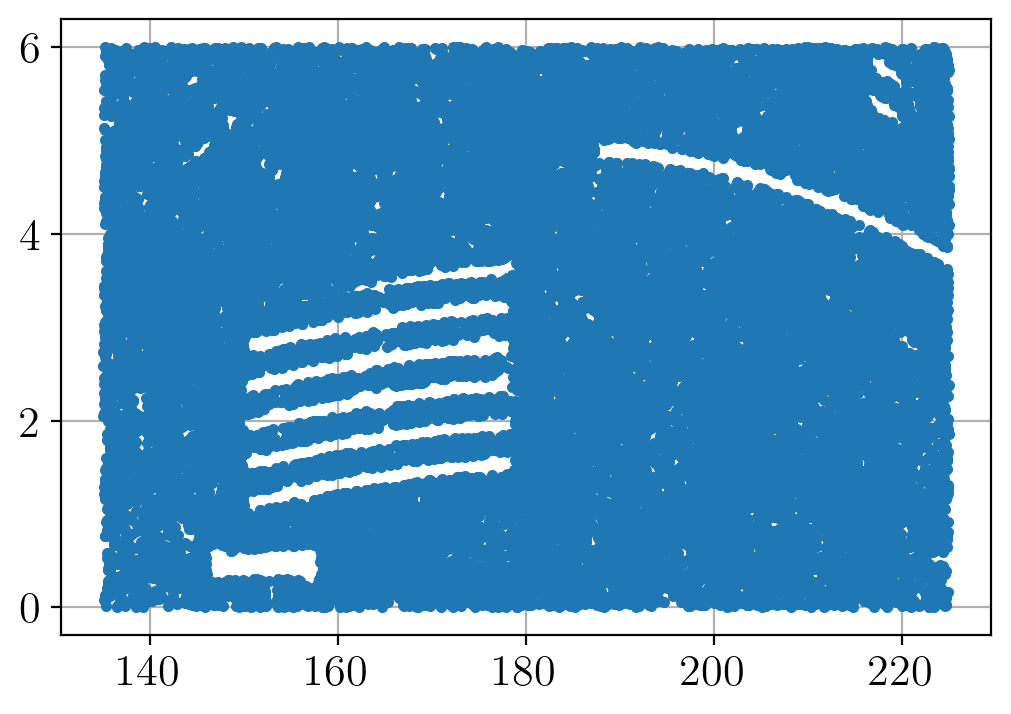

In [4]:
# The file is huge, so let's work with a small slice on the sky
sdssra = np.logical_and(sdssa['RA'] > 135., sdssa['RA']<225.)
sdssdec = np.logical_and(sdssa['DEC'] > 0., sdssa['DEC']<6.)
sdss = sdssa[np.logical_and(sdssra, sdssdec)]
plt.plot(sdss['RA'],sdss['DEC'],'.')
plt.grid();

In [5]:
from astropy.cosmology import FlatLambdaCDM
lcdm = FlatLambdaCDM(Om0=0.3, H0=100.)
d = lcdm.comoving_distance(sdss['Z']).value

Let's make a "pie diagram".

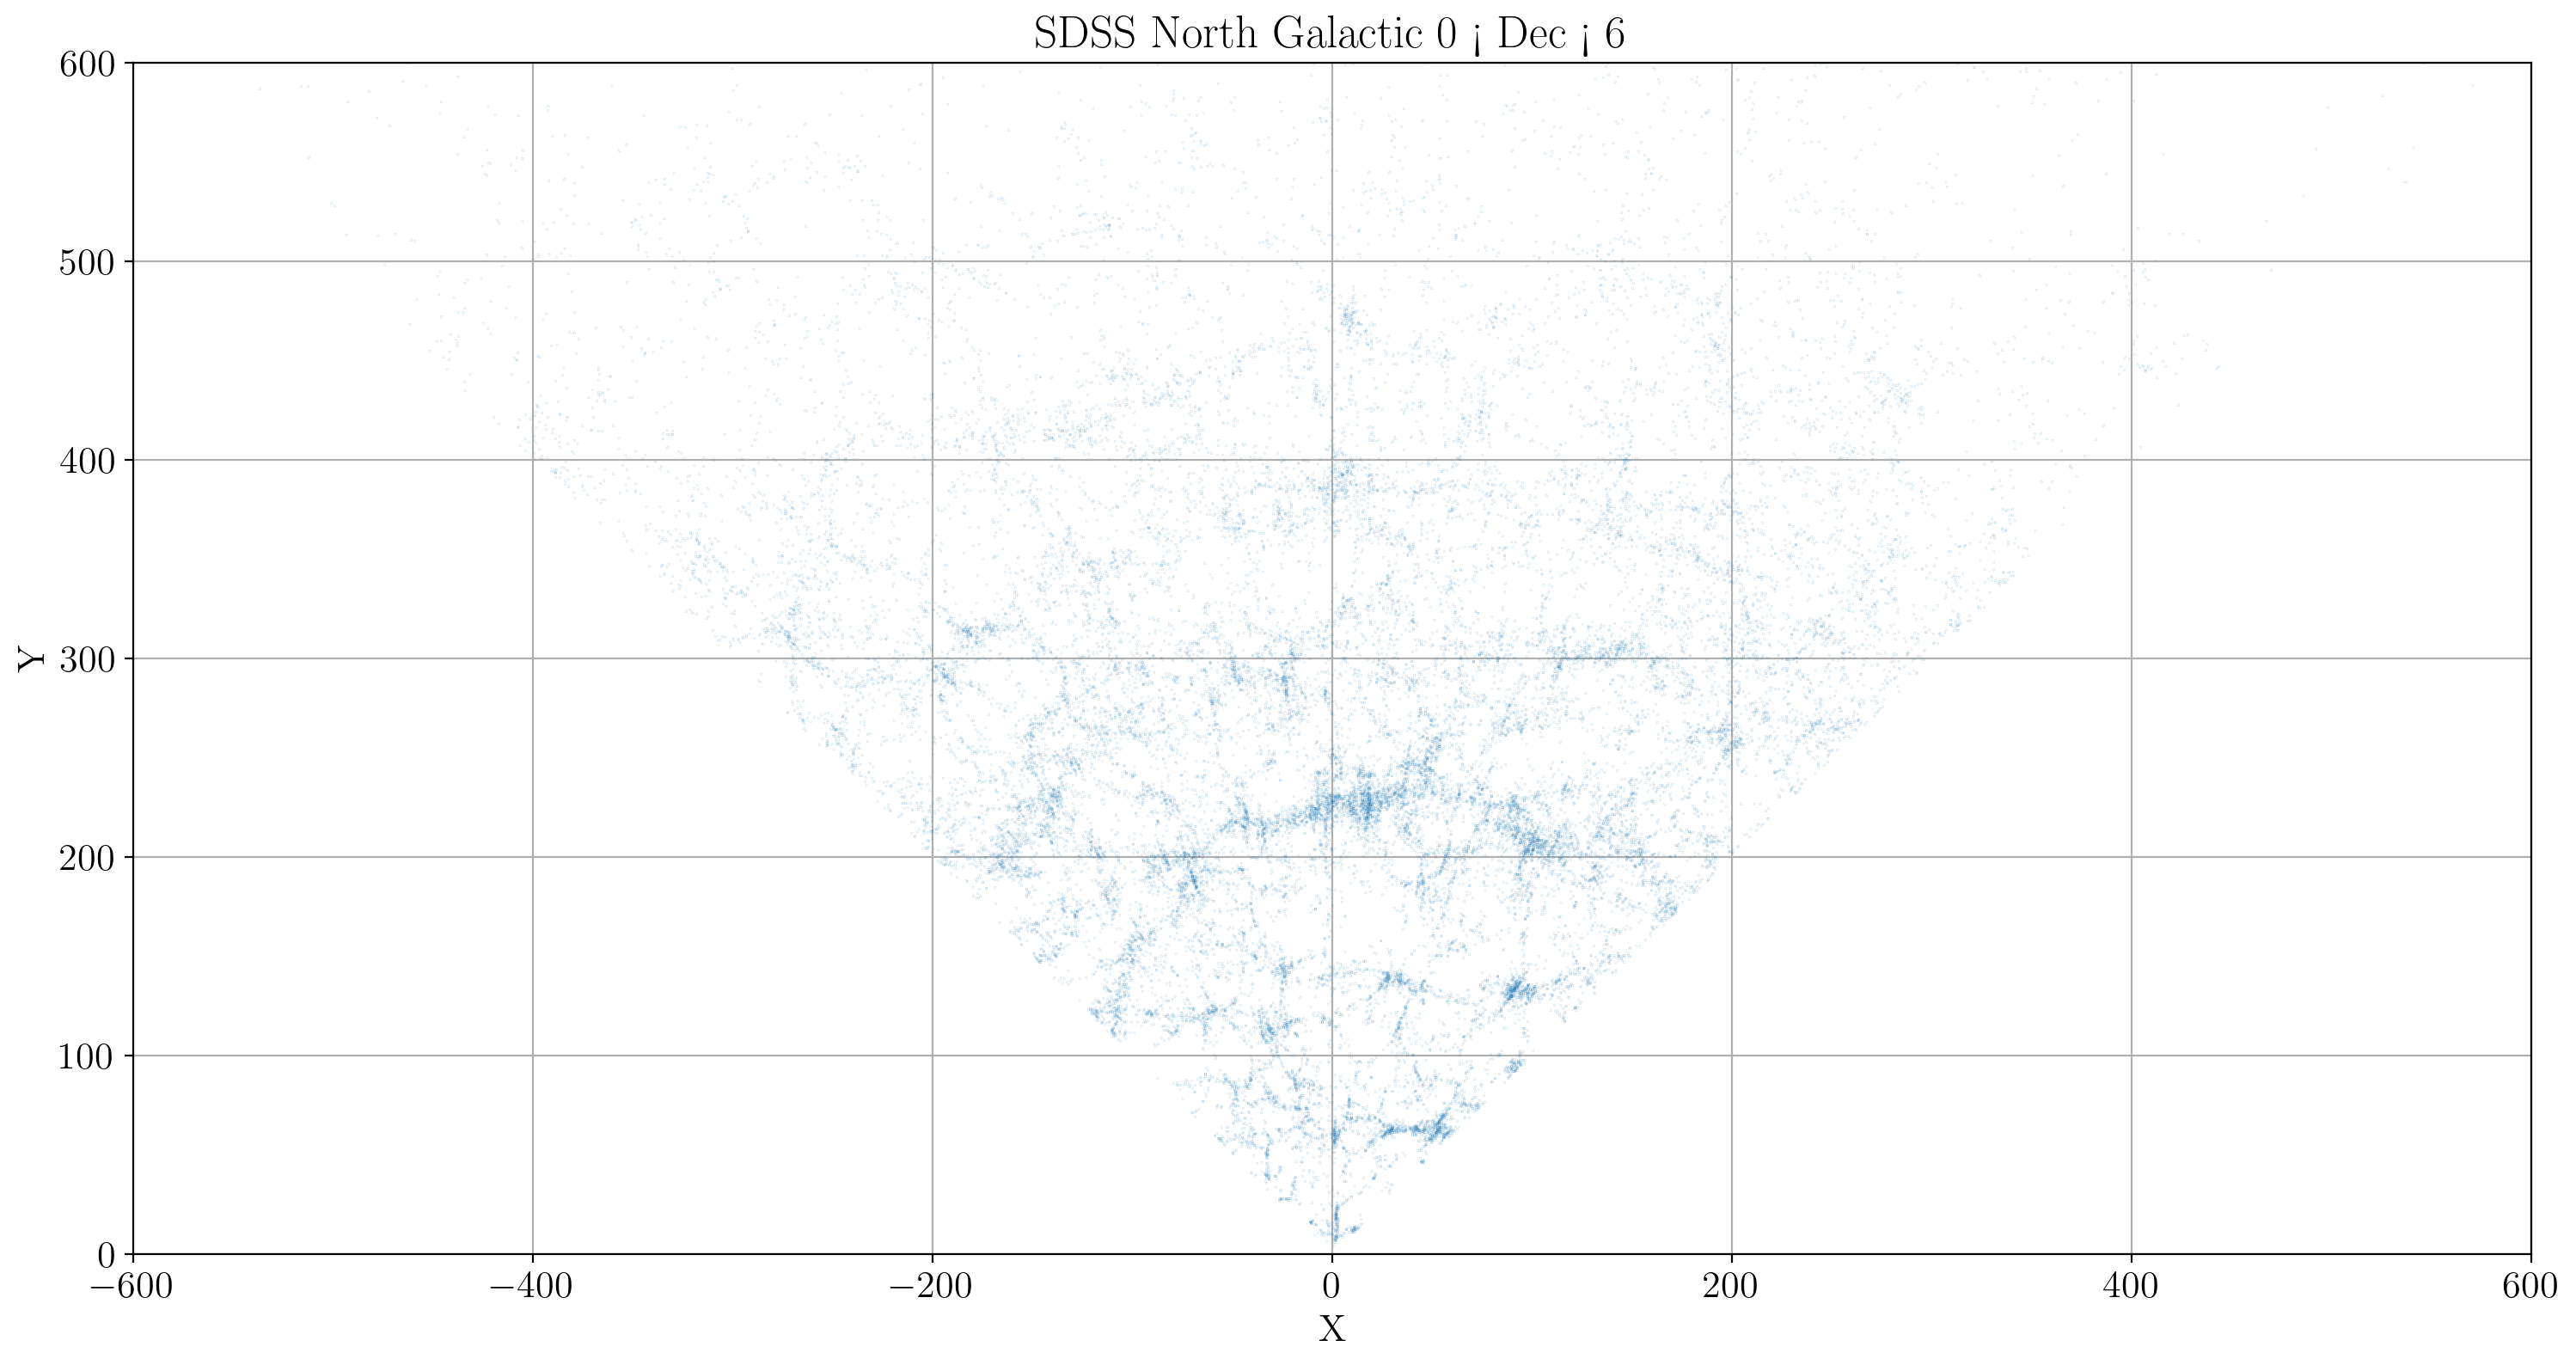

In [6]:
fig = plt.figure(figsize=(18,9))
ax = fig.add_subplot(111)
x = d*np.cos((270-sdss['RA'])/180.*np.pi)
y = d*np.sin((270.-sdss['RA'])/180.*np.pi)
plt.plot(x,y,marker="o", lw=0, ms=8./fig.dpi);
ax.set_xlim(-600,600)
ax.set_ylim(0.,600)
plt.grid()
plt.xlabel('X')
plt.ylabel('Y')
plt.title("SDSS North Galactic 0 < Dec < 6");

Is that not beautiful? The structure at $X \sim 0$, $Y \sim 220$ is part of the Sloan Great Wall. 

In [7]:
sdss = sdss[np.logical_and(sdss['Z'] > 0.05, sdss['Z'] < 0.25)]

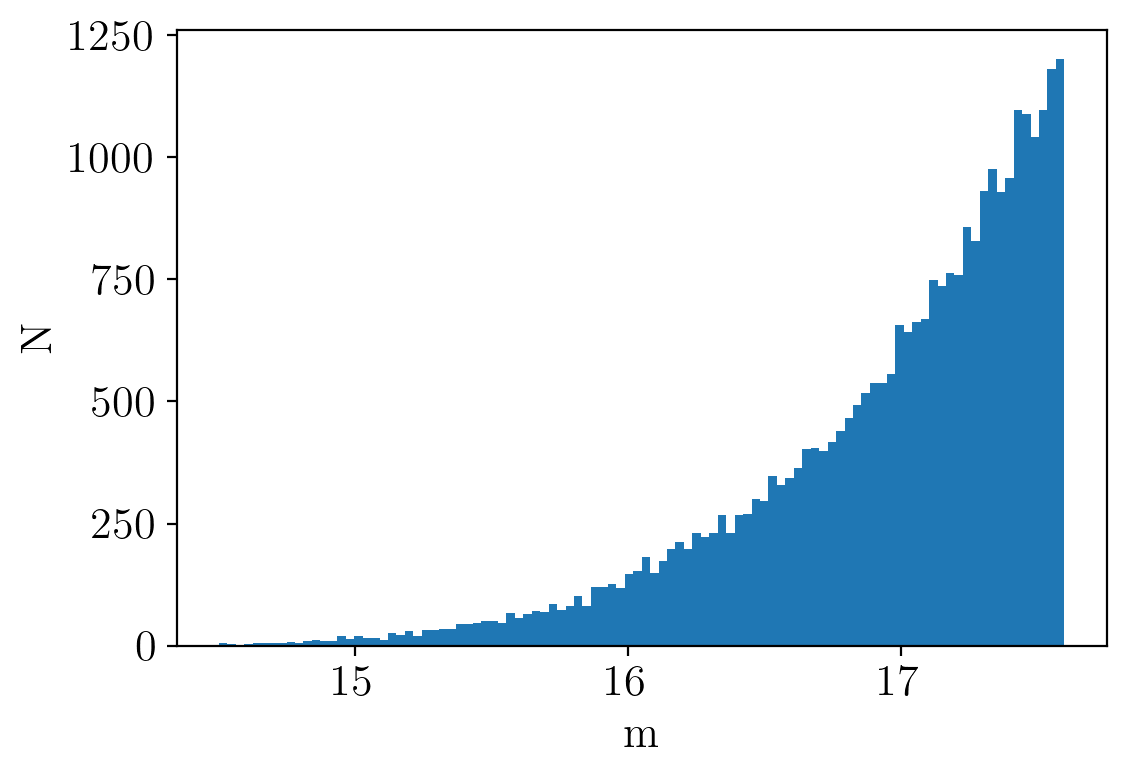

In [8]:
plt.hist(sdss['m'], bins=100)
plt.xlabel('m')
plt.ylabel('N');

Notice that the apparent magnitudes vary from 14.5 to 17.6.

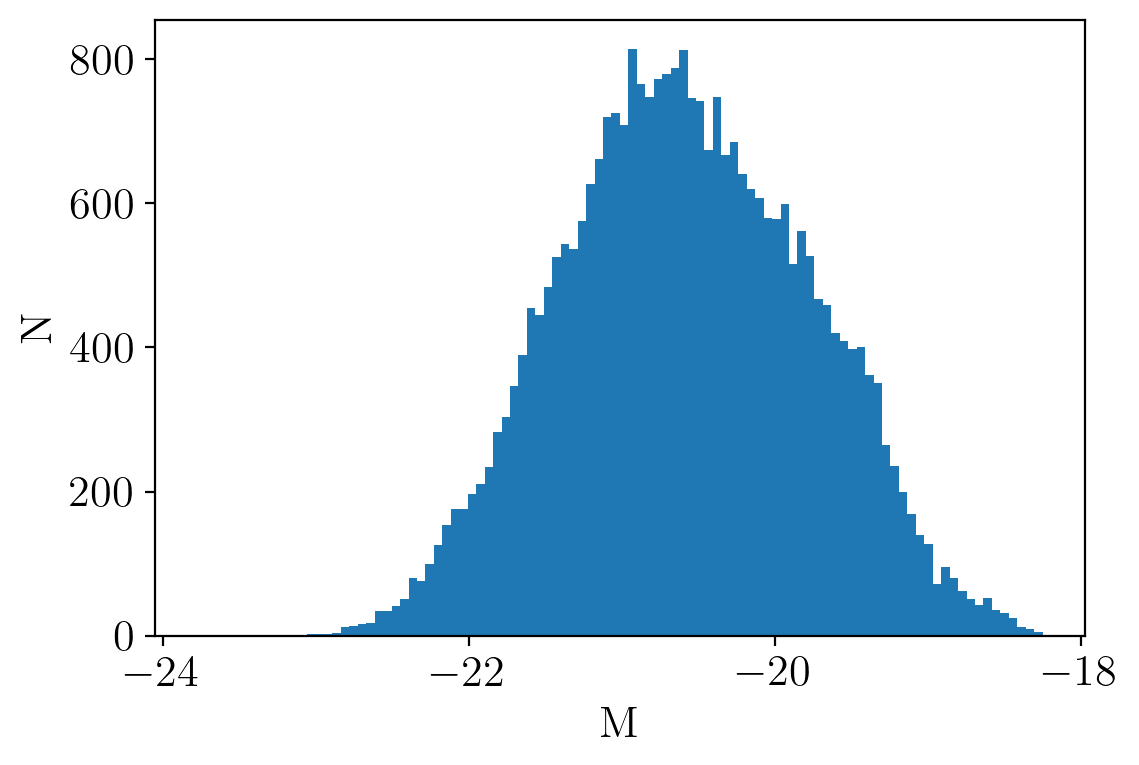

In [9]:
plt.hist(sdss['ABSMr'], bins=100)
plt.xlabel('M')
plt.ylabel('N');

The absolute magnitudes of a *flux-limited* sample do NOT represent the true underlying distribution of absolute magnitudes because of the flux (apparent magnitude) limits.

Let's look at the redshift distrubtion in the flux-limited sample

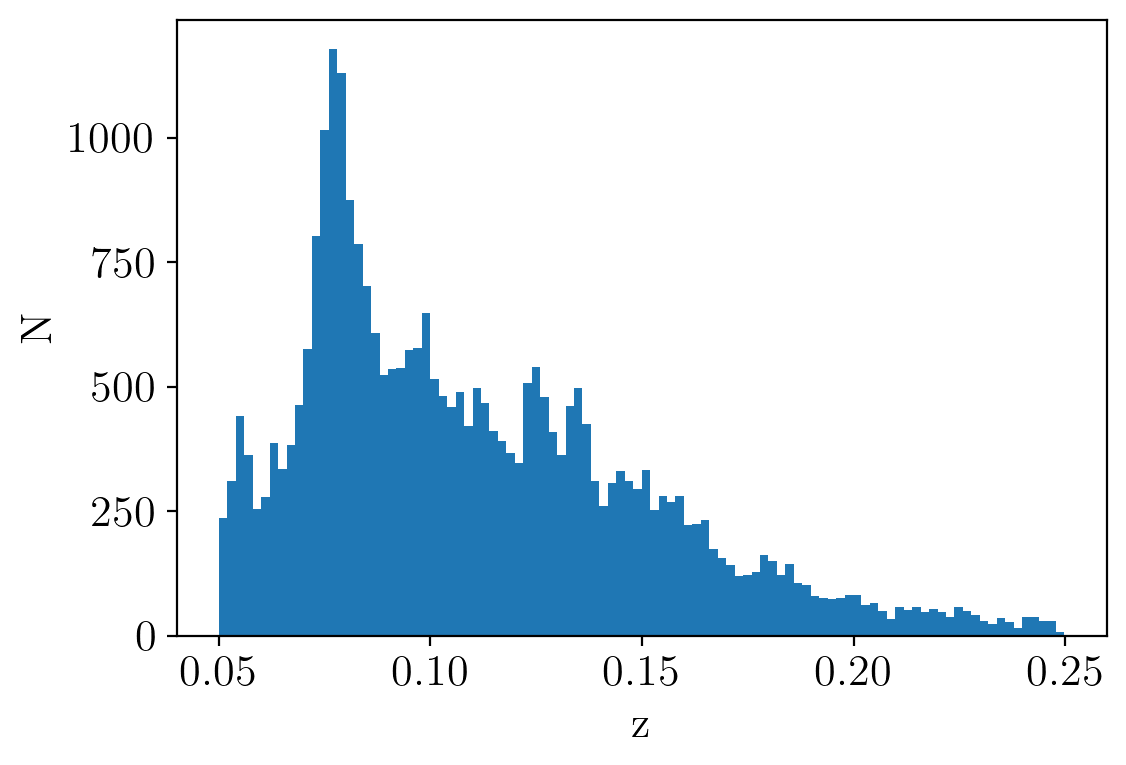

In [10]:
plt.hist(sdss['Z'], bins=100)
plt.xlabel('z')
plt.ylabel('N');

The usual conversion from apparent magnitudes to absolute magnitudes depends on the luminosity distance and the $K$-correction

$$
M = m - 5 \log_{10}\frac{{D_L}}{10 \mathrm{pc}} - K
$$

In this case the absolute magnitude and the apparent magnitude are given for each galaxy, so we know the value of 
$$
5 \log_{10}\frac{{D_L}}{10 \mathrm{pc}} + K
$$

This can be used to obtain the absolute magnitude corresponding to the apparent magnitude limits.


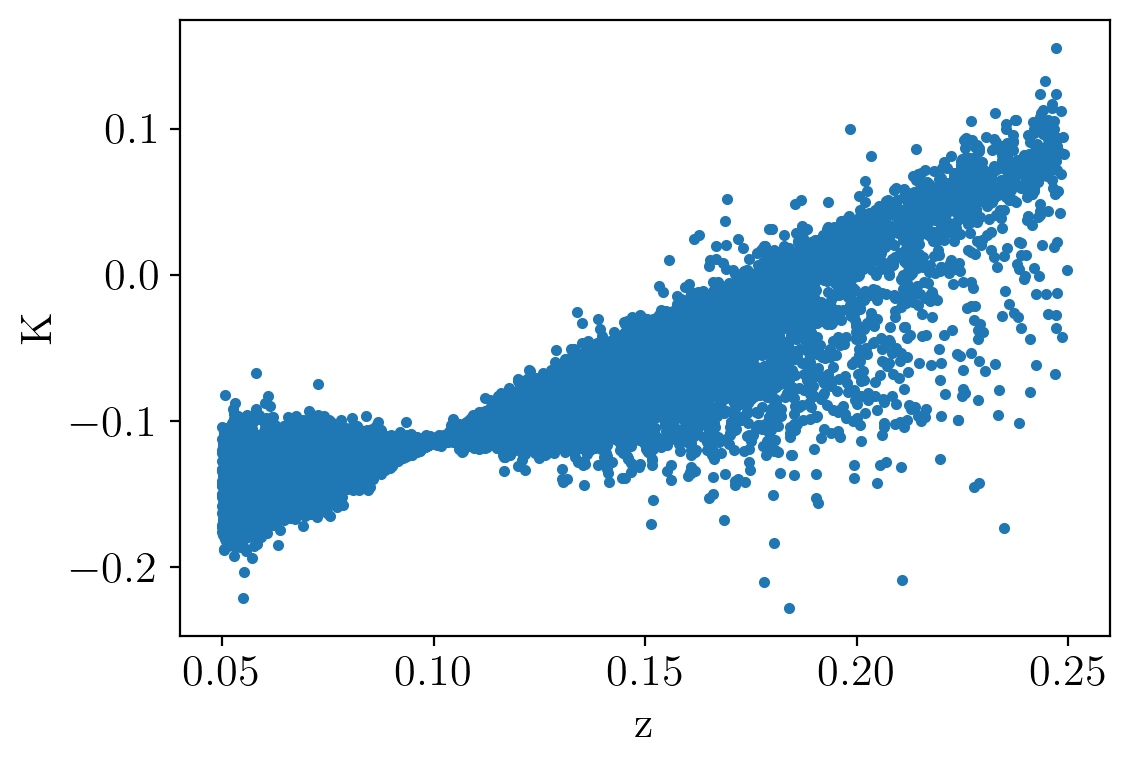

In [11]:
import astropy.units as u
dl = lcdm.luminosity_distance(sdss['Z']) # calculate luminosity distance for LCDM
distmod = 5.*np.log10(dl/(10*u.pc)) # and the distance modulus

magdiff = sdss['m']-sdss['ABSMr']
plt.plot(sdss['Z'], magdiff-distmod,'.')
plt.xlabel('z')
plt.ylabel('K');

Finally, we can calculate luminosities in solar units using the absolute magnitude of the Sun: 4.76

In [12]:
# Magnitude of the Sun in the r band
mag_sun = 4.76

def mag_to_solar(M, Msun):
    return 10.**(-0.4*(M-Msun))

Now fit the data using the same routine as above. 

Print your best fits for the parameters, their marginalized uncertainties and the covariance matrix. If you used an MCMC fitting method like ``emcee`` show the chains and corner plots.

## Repeat for red and blue subsamples

Use $u-r = 2.2$ to divide the sample into red and blue galaxy subsamples and compute the LF parameters from each.

Are they consistent with each other? With the fit to all galaxies?